# Midterm Review

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

import warnings
warnings.simplefilter("ignore")


In [2]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


## Python and Arrays

Fall 2020 Midterm Q4

For each question below, write Python code to answer the question using what we have taught you in this class.
If we ran your Python code, it should evaluate to the answer to the question.


a) This year my salary is $`BASE_SALARY`. I just learned I will receive a 12% raise. What will my
salary be next year, in dollars?

f) An array containing the first 100 squares, i.e., 1, 4, 9, 16, . . . , 10000. The square of a number is
that number to the power of 2.

bonus) The number of non-zero elements in the array of integers `arr`.

In [3]:
# datascience
arr = make_array(3, 2, 1, 0, 0, 4, -4)
...


Ellipsis

In [4]:
# polars
arr_pl = pl.Series('values', [3, 2, 1, 0, 0, 4, -4])
...


Ellipsis

## Histograms

In [5]:
# datascience
top_movies_2017 = Table.read_table('top_movies_2017.csv')
ages = 2026 - top_movies_2017.column('Year')
top_movies_2017 = top_movies_2017.with_column('Age', ages)
top_movies_2017


Title,Studio,Gross,Gross (Adjusted),Year,Age
Gone with the Wind,MGM,198676459,1796176700,1939,87
Star Wars,Fox,460998007,1583483200,1977,49
The Sound of Music,Fox,158671368,1266072700,1965,61
E.T.: The Extra-Terrestrial,Universal,435110554,1261085000,1982,44
Titanic,Paramount,658672302,1204368000,1997,29
The Ten Commandments,Paramount,65500000,1164590000,1956,70
Jaws,Universal,260000000,1138620700,1975,51
Doctor Zhivago,MGM,111721910,1103564200,1965,61
The Exorcist,Warner Brothers,232906145,983226600,1973,53
Snow White and the Seven Dwarves,Disney,184925486,969010000,1937,89


In [6]:
# polars
top_movies_2017_pl = pl.read_csv('top_movies_2017.csv', eol_char='\r')
ages_pl = 2026 - top_movies_2017_pl.get_column('Year')
top_movies_2017_pl = top_movies_2017_pl.with_columns(pl.Series('Age', ages_pl))
top_movies_2017_pl


Title,Studio,Gross,Gross (Adjusted),Year,Age
str,str,i64,i64,i64,i64
"""Gone with the Wind""","""MGM""",198676459,1796176700,1939,87
"""Star Wars""","""Fox""",460998007,1583483200,1977,49
"""The Sound of Music""","""Fox""",158671368,1266072700,1965,61
"""E.T.: The Extra-Terrestrial""","""Universal""",435110554,1261085000,1982,44
"""Titanic""","""Paramount""",658672302,1204368000,1997,29
…,…,…,…,…,…
"""9 to 5""","""Fox""",103290500,341357800,1980,46
"""Batman v Superman: Dawn of Jus…","""Warner Brothers""",330360194,340137000,2016,10
"""The Firm""","""Paramount""",158348367,340028200,1993,33


In [7]:
# datascience
equally_spaced_bins = np.arange(0, 120, 20)
top_movies_2017.bin('Age', bins=equally_spaced_bins)


bin,Age count
0,46
20,68
40,50
60,26
80,9
100,0


In [8]:
# polars
equally_spaced_bins_pl = pl.int_range(0, 120, 20, eager=True)
top_movies_2017_pl.get_column('Age').hist(bins=(equally_spaced_bins_pl).to_list()).rename({'breakpoint': 'bin', 'count': 'Age count'}).drop('category')


bin,Age count
f64,u32
20.0,47
40.0,69
60.0,48
80.0,28
100.0,7


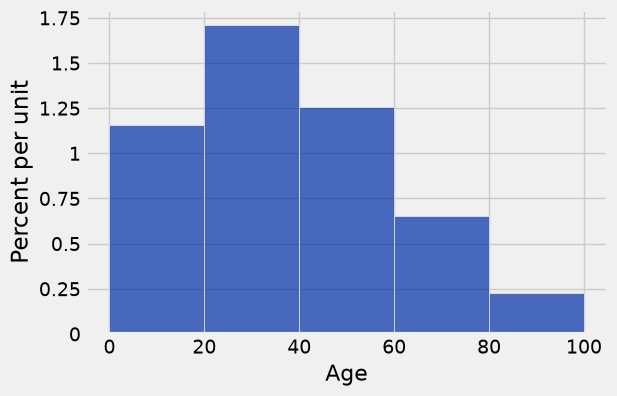

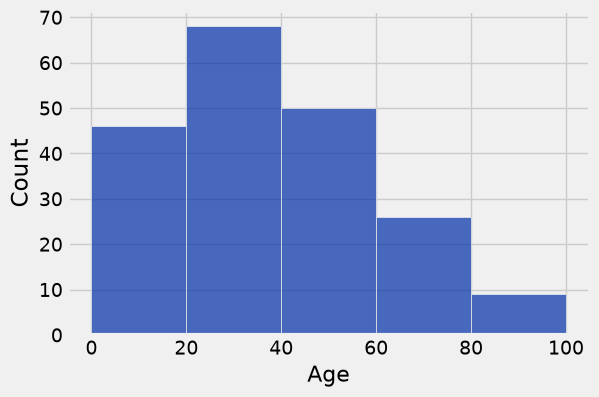

In [9]:
# datascience
top_movies_2017.hist('Age', bins=equally_spaced_bins)
top_movies_2017.hist('Age', bins=equally_spaced_bins, normed=False)


In [10]:
# polars
# hvplot
top_movies_2017_pl.hvplot.hist(y='Age', normed=True, bins=(equally_spaced_bins_pl).to_list())
top_movies_2017_pl.hvplot.hist(y='Age', normed=False, bins=(equally_spaced_bins_pl).to_list())


:Histogram   [Age]   (Count)

In [11]:
# datascience
unequally_spaced_bins = make_array(0, 20, 40, 80, 100)
top_movies_2017.bin('Age', bins=unequally_spaced_bins)


bin,Age count
0,46
20,68
40,76
80,9
100,0


In [12]:
# polars
unequally_spaced_bins_pl = pl.Series('values', [0, 20, 40, 80, 100])
top_movies_2017_pl.get_column('Age').hist(bins=(unequally_spaced_bins_pl).to_list()).rename({'breakpoint': 'bin', 'count': 'Age count'}).drop('category')


bin,Age count
f64,u32
20.0,47
40.0,69
80.0,76
100.0,7


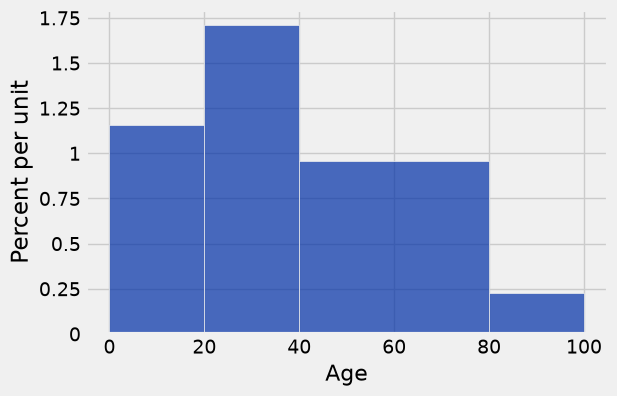

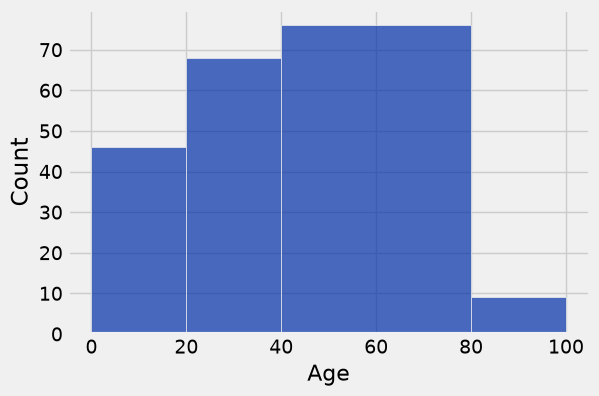

In [13]:
# datascience
top_movies_2017.hist('Age', bins=unequally_spaced_bins)
top_movies_2017.hist('Age', bins=unequally_spaced_bins, normed=False)


In [14]:
# polars
# hvplot
top_movies_2017_pl.hvplot.hist(y='Age', normed=True, bins=(unequally_spaced_bins_pl).to_list())
top_movies_2017_pl.hvplot.hist(y='Age', normed=False, bins=(unequally_spaced_bins_pl).to_list())


:Histogram   [Age]   (Count)

## Functions

### Example: A function that takes the year of birth of a person and produces their age in years. ###

In [15]:
def age(year):
    ...
    return num

In [16]:
# datascience
age(1980)


NameError: name 'num' is not defined

In [17]:
# polars
age(1980)


NameError: name 'num' is not defined

Now add some bells and whistles.

Take person's name and year of birth (two arguments). Produce a sentence that states how old they are.

In [18]:
def name_and_age(name, year):
    return ...

### Example: Add a column to `ages` table that has a person's "name and age" sentence.

In [19]:
# datascience
ages = Table().with_columns(
    'Person', make_array('Jim', 'Pam', 'Michael', 'Creed'),
    'Birth Year', make_array(1985, 1988, 1967, 1904)
)
ages


Person,Birth Year
Jim,1985
Pam,1988
Michael,1967
Creed,1904


In [20]:
# polars
ages_pl = pl.DataFrame([
    (pl.Series('values', ['Jim', 'Pam', 'Michael', 'Creed'])).alias('Person'),
    (pl.Series('values', [1985, 1988, 1967, 1904])).alias('Birth Year')
])
ages_pl


Person,Birth Year
str,i64
"""Jim""",1985
"""Pam""",1988
"""Michael""",1967
"""Creed""",1904


In [21]:
# what does apply do?

In [22]:
# how to add this sentence array to the table?

### Example: a function that computes the sum of the first `k` values in a column of a table.

In [23]:
t = top_movies_2017                 # A generic name for an example table
label = 'Gross (Adjusted)'          # A generic name for an example column label
k = 5                               # A generic name for an example value of k

...

Ellipsis

In [24]:
# datascience
def sum_first_k(t, label, k):
    "Sum the first k values in the label column of Table t."
    return ...


In [25]:
# polars
def sum_first_k_pl(t, label, k):
    "Sum the first k values in the label column of Table t."
    return ...


In [26]:
sum_first_k(top_movies_2017, 'Gross (Adjusted)', 5)

Ellipsis